In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sqlite3

In [9]:
from google.colab import files

uploaded = files.upload()

Saving sample_-_superstore.xls to sample_-_superstore.xls


In [14]:
df = pd.read_excel(
    "sample_-_superstore.xls",
    sheet_name="Orders"
)

df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2023-103800,2023-01-03,2023-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512
1,2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870
2,3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717
3,4,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748
4,5,US-2023-141817,2023-01-05,2023-01-12,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840


In [15]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

df.info()

Rows: 10194
Columns: 21
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Row ID          10194 non-null  int64         
 1   Order ID        10194 non-null  object        
 2   Order Date      10194 non-null  datetime64[ns]
 3   Ship Date       10194 non-null  datetime64[ns]
 4   Ship Mode       10194 non-null  object        
 5   Customer ID     10194 non-null  object        
 6   Customer Name   10194 non-null  object        
 7   Segment         10194 non-null  object        
 8   Country/Region  10194 non-null  object        
 9   City            10194 non-null  object        
 10  State/Province  10194 non-null  object        
 11  Postal Code     10194 non-null  object        
 12  Region          10194 non-null  object        
 13  Product ID      10194 non-null  object        
 14  Category        10194 non-null

In [18]:
print(df.columns.tolist())

['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country/Region', 'City', 'State/Province', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']


In [19]:
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
    .str.replace("-", "_")
)

df.columns.tolist()

['row_id',
 'order_id',
 'order_date',
 'ship_date',
 'ship_mode',
 'customer_id',
 'customer_name',
 'segment',
 'country/region',
 'city',
 'state/province',
 'postal_code',
 'region',
 'product_id',
 'category',
 'sub_category',
 'product_name',
 'sales',
 'quantity',
 'discount',
 'profit']

In [20]:
df.head()

,row_id,order_id,order_date,ship_date,ship_mode,customer_id,customer_name,segment,country/region,city,...,postal_code,region,product_id,category,sub_category,product_name,sales,quantity,discount,profit
0,1,US-2023-103800,2023-01-03,2023-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512
1,2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870
2,3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717
3,4,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748
4,5,US-2023-141817,2023-01-05,2023-01-12,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840


In [21]:
df.shape

(10194, 21)

In [22]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   row_id          10194 non-null  int64         
 1   order_id        10194 non-null  object        
 2   order_date      10194 non-null  datetime64[ns]
 3   ship_date       10194 non-null  datetime64[ns]
 4   ship_mode       10194 non-null  object        
 5   customer_id     10194 non-null  object        
 6   customer_name   10194 non-null  object        
 7   segment         10194 non-null  object        
 8   country/region  10194 non-null  object        
 9   city            10194 non-null  object        
 10  state/province  10194 non-null  object        
 11  postal_code     10194 non-null  object        
 12  region          10194 non-null  object        
 13  product_id      10194 non-null  object        
 14  category        10194 non-null  object        
 15  su

In [23]:
missing = df.isnull().sum().sort_values(ascending=False)

missing[missing > 0]

,0


In [26]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [27]:
df = df.drop_duplicates().copy()

print("Rows after duplicate removal:", len(df))

Rows after duplicate removal: 10194


In [28]:
df["order_date"] = pd.to_datetime(df["order_date"])
df["ship_date"] = pd.to_datetime(df["ship_date"])

In [29]:
numeric_columns = [
    "sales",
    "quantity",
    "discount",
    "profit"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

In [30]:
df[
    [
        "order_id",
        "order_date",
        "customer_id",
        "product_id",
        "sales",
        "profit"
    ]
].isnull().sum()

,0
order_id,0
order_date,0
customer_id,0
product_id,0
sales,0
profit,0


In [31]:
df = df.dropna(
    subset=[
        "order_id",
        "order_date",
        "sales",
        "profit"
    ]
)

In [32]:
df["year"] = df["order_date"].dt.year
df["month"] = df["order_date"].dt.month
df["month_name"] = df["order_date"].dt.month_name()
df["quarter"] = "Q" + df["order_date"].dt.quarter.astype(str)

df["year_month"] = (
    df["order_date"]
    .dt.to_period("M")
    .astype(str)
)

In [33]:
df["shipping_days"] = (
    df["ship_date"] - df["order_date"]
).dt.days

In [34]:
print("Final shape:", df.shape)

display(df.head())

print("\nMissing values:")
print(df.isnull().sum().sort_values(ascending=False).head(10))

Final shape: (10194, 27)


,row_id,order_id,order_date,ship_date,ship_mode,customer_id,customer_name,segment,country/region,city,...,sales,quantity,discount,profit,year,month,month_name,quarter,year_month,shipping_days
0,1,US-2023-103800,2023-01-03,2023-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,16.448,2,0.2,5.5512,2023,1,January,Q1,2023-01,4
1,2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,3.540,2,0.8,-5.4870,2023,1,January,Q1,2023-01,4
2,3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,11.784,3,0.2,4.2717,2023,1,January,Q1,2023-01,4
3,4,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,272.736,3,0.2,-64.7748,2023,1,January,Q1,2023-01,4
4,5,US-2023-141817,2023-01-05,2023-01-12,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,19.536,3,0.2,4.8840,2023,1,January,Q1,2023-01,7



Missing values:
row_id            0
order_id          0
order_date        0
ship_date         0
ship_mode         0
customer_id       0
customer_name     0
segment           0
country/region    0
city              0
dtype: int64


#Business KPIs

In [36]:
#Calculate total sales:
total_sales = df["sales"].sum()

print(f"Total Sales: ${total_sales:,.2f}")

Total Sales: $2,326,534.35


In [38]:
#Total profit:
total_profit = df["profit"].sum()

print(f"Total Profit: ${total_profit:,.2f}")

Total Profit: $292,296.81


In [39]:
#Number of orders:
total_orders = df["order_id"].nunique()

print("Total Orders:", total_orders)

Total Orders: 5111


In [41]:
#Number of customers:
total_customers = df["customer_id"].nunique()

print("Total Customers:", total_customers)

Total Customers: 804


In [42]:
#Total quantity:
total_quantity = df["quantity"].sum()

print("Total Quantity:", total_quantity)

Total Quantity: 38654


In [44]:
#Profit margin:
profit_margin = (
    total_profit / total_sales
) * 100

print(f"Profit Margin: {profit_margin:.2f}%")

Profit Margin: 12.56%


In [45]:
#Average order value:
average_order_value = (
    total_sales / total_orders
)

print(f"Average Order Value: ${average_order_value:,.2f}")

Average Order Value: $455.20


#KPI table:

In [46]:
kpis = pd.DataFrame({
    "Metric": [
        "Total Sales",
        "Total Profit",
        "Total Orders",
        "Total Customers",
        "Total Quantity",
        "Profit Margin %",
        "Average Order Value"
    ],
    "Value": [
        total_sales,
        total_profit,
        total_orders,
        total_customers,
        total_quantity,
        profit_margin,
        average_order_value
    ]
})

display(kpis)

,Metric,Value
0,Total Sales,2.326534e+06
1,Total Profit,2.922968e+05
2,Total Orders,5.111000e+03
3,Total Customers,8.040000e+02
4,Total Quantity,3.865400e+04
5,Profit Margin %,1.256361e+01
6,Average Order Value,4.552014e+02


#Business questions

In [48]:
#How are sales performing over time?
monthly = (
    df.groupby("year_month")
    .agg(
        Sales=("sales", "sum"),
        Profit=("profit", "sum")
    )
    .reset_index()
)

display(monthly.head())

,year_month,Sales,Profit
0,2023-01,14518.055,2539.3907
1,2023-02,4519.892,862.3084
2,2023-03,56933.909,693.4499
3,2023-04,28295.345,3488.8352
4,2023-05,26319.767,3196.3918


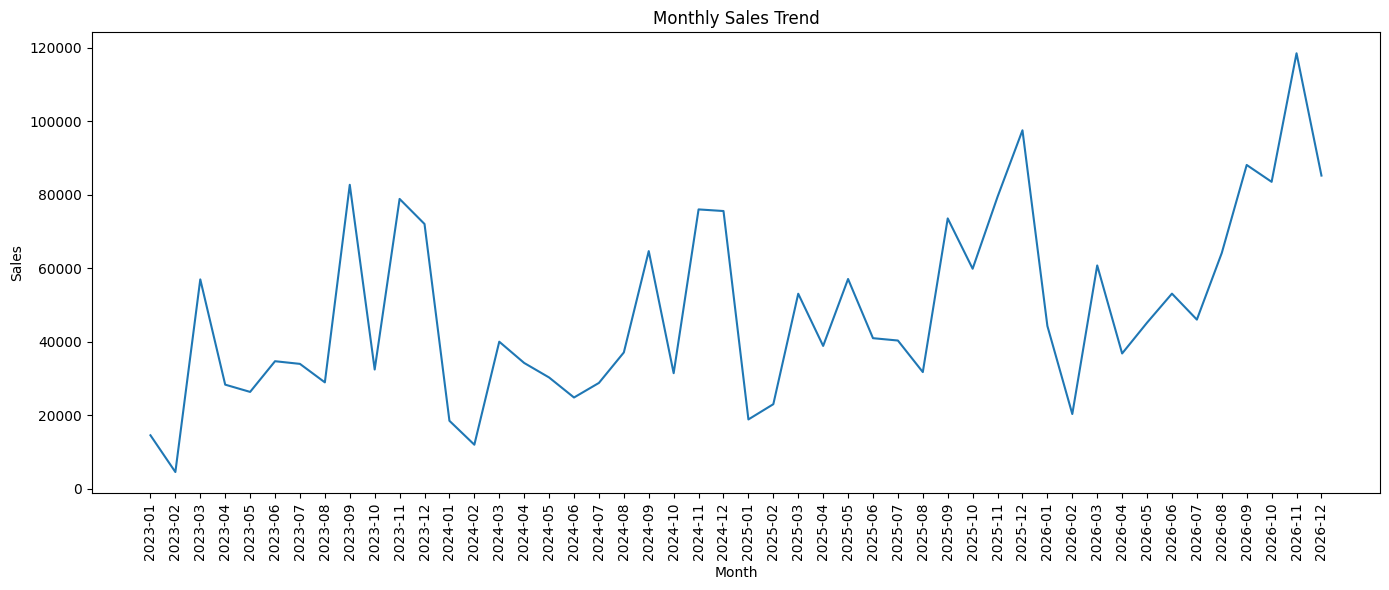

In [49]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly["year_month"],
    monthly["Sales"]
)

plt.xticks(rotation=90)
plt.xlabel("Month")
plt.ylabel("Sales")
plt.title("Monthly Sales Trend")

plt.tight_layout()
plt.show()

In [50]:
#performance by Category:
category_analysis = (
    df.groupby("category")
    .agg(
        Sales=("sales", "sum"),
        Profit=("profit", "sum"),
        Quantity=("quantity", "sum")
    )
    .sort_values("Sales", ascending=False)
)

display(category_analysis)

,Sales,Profit,Quantity
category,,,
Technology,839893.2790,146543.3756,7017
Furniture,754747.7613,19729.9956,8369
Office Supplies,731893.3140,126023.4434,23268


In [51]:
#Sub-Category:
subcategory_analysis = (
    df.groupby("sub_category")
    .agg(
        Sales=("sales", "sum"),
        Profit=("profit", "sum"),
        Quantity=("quantity", "sum")
    )
    .sort_values("Sales", ascending=False)
)

display(subcategory_analysis)

,Sales,Profit,Quantity
sub_category,,,
Chairs,335768.2490,27223.5323,2431
Phones,331842.6400,45050.8265,3357
Storage,224644.5540,21285.1115,3191
Tables,208020.1820,-17753.2061,1261
Binders,207354.8810,31426.1003,6071
Machines,189925.0310,3461.9769,442
Accessories,167380.3180,41936.6357,2976
Copiers,150745.2900,56093.9365,242
Bookcases,115361.2043,-3632.0736,878


In [52]:
#Identify loss-making subcategories:
loss_subcategories = (
    subcategory_analysis[
        subcategory_analysis["Profit"] < 0
    ]
    .sort_values("Profit")
)

display(loss_subcategories)

,Sales,Profit,Quantity
sub_category,,,
Tables,208020.1820,-17753.2061,1261
Bookcases,115361.2043,-3632.0736,878
Supplies,46725.4980,-1171.3945,653


In [54]:
#Analyze regions:
region_analysis = (
    df.groupby("region")
    .agg(
        Sales=("sales", "sum"),
        Profit=("profit", "sum"),
        Orders=("order_id", "nunique"),
        Customers=("customer_id", "nunique")
    )
    .sort_values("Sales", ascending=False)
)

display(region_analysis)

,Sales,Profit,Orders,Customers
region,,,,
West,739813.6085,110798.8170,1635,686
East,691828.1680,94883.2603,1475,685
Central,503170.6728,39865.3070,1179,629
South,391721.9050,46749.4303,822,512


In [56]:
#Analyze customer segments:
segment_analysis = (
    df.groupby("segment")
    .agg(
        Sales=("sales", "sum"),
        Profit=("profit", "sum"),
        Orders=("order_id", "nunique")
    )
    .sort_values("Sales", ascending=False)
)

display(segment_analysis)

,Sales,Profit,Orders
segment,,,
Consumer,1.170660e+06,136371.4463,2628
Corporate,7.158061e+05,94249.6400,1552
Home Office,4.400684e+05,61675.7283,931


In [57]:
#Top 10 Products by Sales:
top_products = (
    df.groupby("product_name")
    .agg(
        Sales=("sales", "sum"),
        Profit=("profit", "sum"),
        Quantity=("quantity", "sum")
    )
    .sort_values("Sales", ascending=False)
    .head(10)
)

display(top_products)

,Sales,Profit,Quantity
product_name,,,
Canon imageCLASS 2200 Advanced Copier,61599.824,2.519993e+04,20
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,27453.384,7.753039e+03,31
Cisco TelePresence System EX90 Videoconferencing Unit,22638.480,-1.811078e+03,6
HON 5400 Series Task Chairs for Big and Tall,21870.576,3.410605e-13,39
GBC DocuBind TL300 Electric Binding System,19823.479,2.233505e+03,37
GBC Ibimaster 500 Manual ProClick Binding System,19024.500,7.609800e+02,48
Hewlett Packard LaserJet 3310 Copier,18839.686,6.983884e+03,38
"HP Designjet T520 Inkjet Large Format Printer - 24"" Color",18374.895,4.094977e+03,12
GBC DocuBind P400 Electric Binding System,17965.068,-1.878166e+03,27


In [58]:
#Top 10 Products by Profit:
top_profit_products = (
    df.groupby("product_name")
    .agg(
        Sales=("sales", "sum"),
        Profit=("profit", "sum")
    )
    .sort_values("Profit", ascending=False)
    .head(10)
)

display(top_profit_products)

,Sales,Profit
product_name,,
Canon imageCLASS 2200 Advanced Copier,61599.824,25199.9280
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,27453.384,7753.0390
Hewlett Packard LaserJet 3310 Copier,18839.686,6983.8836
Canon PC1060 Personal Laser Copier,11619.834,4570.9347
"HP Designjet T520 Inkjet Large Format Printer - 24"" Color",18374.895,4094.9766
Ativa V4110MDD Micro-Cut Shredder,7699.890,3772.9461
"3D Systems Cube Printer, 2nd Generation, Magenta",14299.890,3717.9714
Plantronics Savi W720 Multi-Device Wireless Headset System,9367.290,3696.2820
Ibico EPK-21 Electric Binding System,15875.916,3345.2823


In [59]:
#10 biggest loss-making products:
loss_products = (
    df.groupby("product_name")
    .agg(
        Sales=("sales", "sum"),
        Profit=("profit", "sum")
    )
    .sort_values("Profit")
    .head(10)
)

display(loss_products)

,Sales,Profit
product_name,,
Cubify CubeX 3D Printer Double Head Print,11099.963,-8879.9704
Lexmark MX611dhe Monochrome Laser Printer,16829.901,-4589.9730
Cubify CubeX 3D Printer Triple Head Print,7999.980,-3839.9904
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases,9917.640,-2876.1156
Bush Advantage Collection Racetrack Conference Table,9544.725,-1934.3976
GBC DocuBind P400 Electric Binding System,17965.068,-1878.1662
Cisco TelePresence System EX90 Videoconferencing Unit,22638.480,-1811.0784
Martin Yale Chadless Opener Electric Letter Opener,16656.200,-1299.1836
Balt Solid Wood Round Tables,6518.754,-1201.0581


In [60]:
#Analyze customers:
customer_analysis = (
    df.groupby(
        ["customer_id", "customer_name"]
    )
    .agg(
        Sales=("sales", "sum"),
        Profit=("profit", "sum"),
        Orders=("order_id", "nunique")
    )
    .sort_values("Sales", ascending=False)
)

display(customer_analysis.head(10))

,,Sales,Profit,Orders
customer_id,customer_name,,,
SM-20320,Sean Miller,25043.050,-1980.7393,5
TC-20980,Tamara Chand,19052.218,8981.3239,5
RB-19360,Raymond Buch,15117.339,6976.0959,6
TA-21385,Tom Ashbrook,14595.620,4703.7883,4
AB-10105,Adrian Barton,14473.571,5444.8055,10
KL-16645,Ken Lonsdale,14175.229,806.8550,12
SC-20095,Sanjit Chand,14142.334,5757.4119,9
HL-15040,Hunter Lopez,12873.298,5622.4292,6
SE-20110,Sanjit Engle,12209.438,2650.6769,11


In [62]:
#Analyze discounts versus profitability:
#Are high discounts hurting profitability?
discount_analysis = (
    df.groupby("discount")
    .agg(
        Sales=("sales", "sum"),
        Profit=("profit", "sum"),
        Orders=("order_id", "nunique")
    )
    .reset_index()
)

display(discount_analysis)

,discount,Sales,Profit,Orders
0,0.00,1.105324e+06,326718.5872,2714
1,0.10,5.495250e+04,9099.9700,91
2,0.15,2.755852e+04,1418.9915,51
3,0.20,7.739394e+05,91079.9517,2440
4,0.30,1.044741e+05,-10513.4456,214
5,0.32,1.449346e+04,-2391.1377,27
6,0.40,1.164978e+05,-23086.3742,186
7,0.45,5.484974e+03,-2493.1111,10
8,0.50,5.891854e+04,-20506.4281,64
9,0.60,7.105940e+03,-6164.3472,138


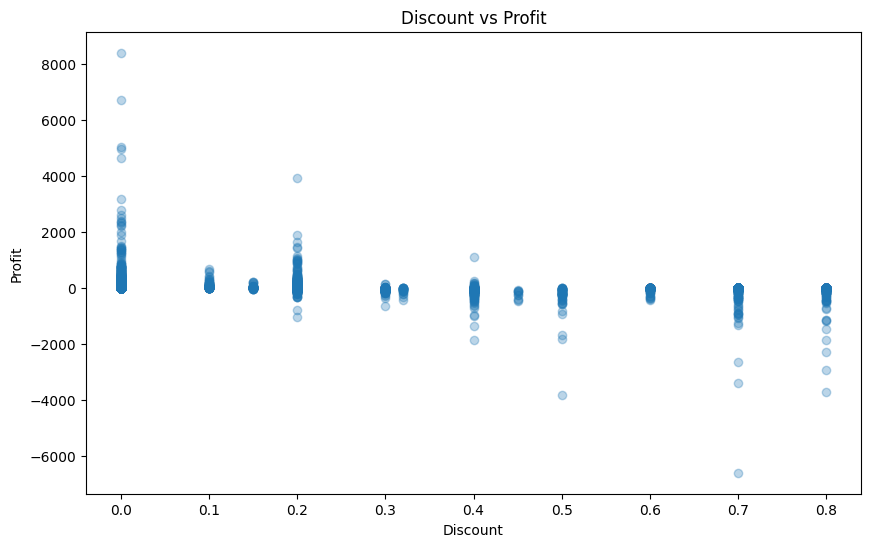

In [63]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["discount"],
    df["profit"],
    alpha=0.3
)

plt.xlabel("Discount")
plt.ylabel("Profit")
plt.title("Discount vs Profit")

plt.show()

## Key Finding

Higher discount levels appear to be associated with lower profitability.
Some products generate strong revenue but negative profit, suggesting
discounting and pricing strategy should be reviewed.

In [65]:
df.to_csv("superstore_cleaned.csv", index=False)

from google.colab import files
files.download("superstore_cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>